<a href="https://colab.research.google.com/github/tusar-verma/Machine-learning-2c2026/blob/feat%2Fnotebook-8/notebooks/notebook_08_descenso_gradiente-published.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Descenso por gradiente

Vamos a explorar el método de descenso por gradiente para el cómputo de una regresión lineal.


In [1]:
import numpy as np
import seaborn as sns
import pandas as pd
from sklearn.datasets import make_regression
from sklearn.metrics import mean_squared_error
from typing import Callable, Dict, Optional, Any

#### Datos para trabajar

Tenemos los siguientes datos generados al azar para ser ajustados por una regresión.

In [2]:
bias = 500
X, y, coef = make_regression(n_samples=5000,
                             n_features=3,
                             bias= bias,
                             noise=1, random_state=42, coef=True)

print(f"Generamos una matriz de {X.shape[0]} de observaciones de {X.shape[1]} atributos\n" +
      f"Target en el rango {(round(min(y),2), round(max(y),2))}\n" +
      f"los coeficientes con los que fueron generados son: {coef}")

print(f"Y = {bias} + {' + '.join([str(round(c,2)) + ' * X' + str(idx+1) for idx,c in enumerate(coef)])} + ε")

Generamos una matriz de 5000 de observaciones de 3 atributos
Target en el rango (np.float64(113.11), np.float64(865.44))
los coeficientes con los que fueron generados son: [38.95952484  1.51074456 89.82730651]
Y = 500 + 38.96 * X1 + 1.51 * X2 + 89.83 * X3 + ε


Los datos se ven así:

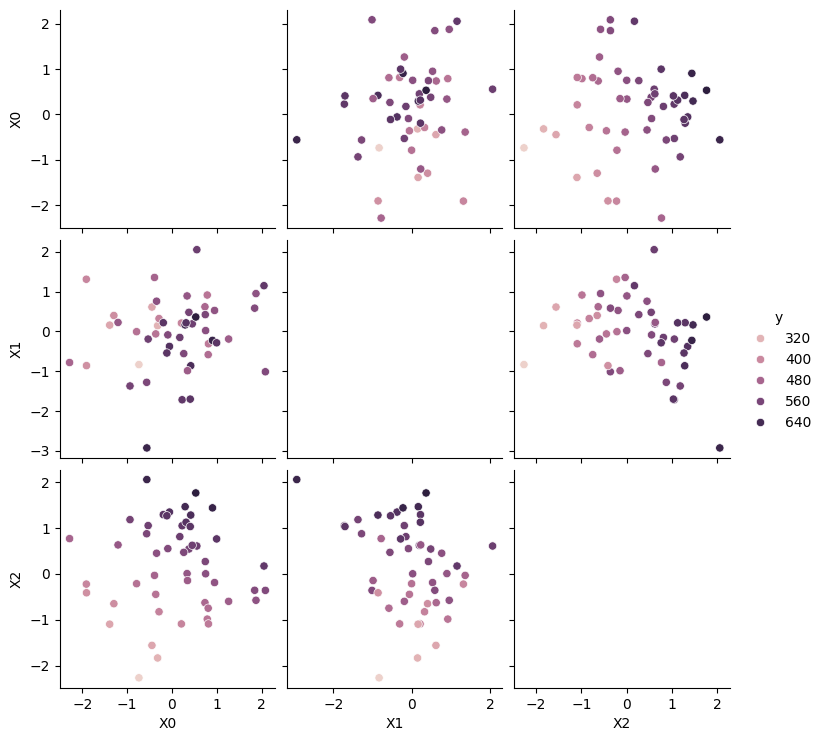

In [3]:
df = pd.DataFrame(X, columns=[f"X{i}" for i in range(X.shape[1])])
df["y"] = y
sns.pairplot(df.sample(50), hue="y")

En este notebook vamos a ver el resultado calculado de diversas formas, por lo que vamos a guardar para cada resultado los w y un valor de error.

In [4]:
# Usamos esta métrica, pero podemos reemplazarla por otra

def error_prediccion(X: np.ndarray, y: np.ndarray, w: np.ndarray) -> float:
    # agrego columna para el intercept
    col_ones = np.ones((X.shape[0], 1))
    X_ext = np.hstack((col_ones, X))

    predicciones = np.dot(X_ext, w)

    return mean_squared_error(predicciones, y)

Los resultados los almacenaremos en un `DataFrame`.

In [5]:
# Guardo los datos para comparaciones posteriores
resultados = pd.DataFrame(columns=["metodo", "w0", "w1", "w2", "w3", "error_prediccion"])

err = error_prediccion(X, y, np.array([bias] + list(coef)))
resultados.loc[len(resultados)] = ["simulacion", bias] + list(coef) + [err]
resultados

,metodo,w0,w1,w2,w3,error_prediccion
0,simulacion,500,38.959525,1.510745,89.827307,1.001549


## Descenso por gradiente

Veamos ahora la función general

In [6]:
def descenso_gradiente(g, dg, z_init, alpha, num_iterations, tol, verbose=False):
    """
    Descenso de gradiente para minimizar g.
    Args:
        g: La función a optimizar.
        dg: El gradiente de la función.
        z_init: Valor inicial.
        alpha: El 'learning rate'.
        num_iterations: Máx iteraciones.
        tol: Tolerancia para la convergencia.
    """
    z = z_init
    for _ in range(num_iterations):
        gradient = dg(z) # gradient vale por ej <0.5, -0.2, -3, 0>
        z_new = z - (alpha * gradient)
        if abs(g(z_new) - g(z)) < tol:
            break
        z = z_new
    return z


Con esto es todo lo que necesitamos de descenso por gradiente.

## Regresión lineal

Podemos generarnos una clase que calcula la regresión lineal utilizando el método de  descenso por gradiente y nos devuelva los pesos correspondientes a los w de la regresión.



In [7]:
from sklearn import preprocessing
from functools import partial

class RegresionLinealDG():

    def __init__(self,
                 func_costo: Callable[..., float],
                 func_costo_grad: Callable[..., np.ndarray],
                 descenso_gradiente_hyperparams: Optional[Dict[str, Any]] = None):
        self.func_costo = func_costo
        self.func_costo_grad = func_costo_grad
        self.descenso_gradiente_hyperparams = descenso_gradiente_hyperparams
        self.collect_info = False

    def fit(self, X: np.ndarray, y: np.ndarray) -> None:
        # agrego columna para el intercept
        col_ones = np.ones((X.shape[0], 1))
        X_train_ext = np.hstack((col_ones, X))

        cost_X_y = partial(self.func_costo, X=X_train_ext, y=y)
        grad_cost_X_y = partial(self.func_costo_grad, X=X_train_ext, y=y)

        w_shape = X_train_ext.shape[1]
        self.w = descenso_gradiente(cost_X_y, grad_cost_X_y,
                        z_init=np.zeros(w_shape),
                        **self.descenso_gradiente_hyperparams)


Con la clase `RegresionLinealDG` ya debemos definir en la creación la función de costo y el gradiente que se utilizan en el método (descenso por grandiente).

Empecemos usando MSE:

$MSE_{X,y} = \frac{1}{n} \sum_{i=1}^{n} (\hat{h}_{w_0,w_1,\ldots,w_p}(x^{(i)}) - y^{(i)})^2$

y su gradiente:

$\nabla_{\mathbf{w}} MSE_{X,y}(w) = \frac{2}{n} \sum_{i=1}^{n} (\hat{h}_{w_0,w_1,\ldots,w_p}(x^{(i)}) - y^{(i)}) * x^{(i)}$



In [8]:
def mse(w: np.ndarray, X: np.ndarray, y: np.ndarray) -> float:
    y_preds = X @ w
    return (1/len(y)) * np.sum((y_preds - y)**2)

def grad_mse(w: np.ndarray, X: np.ndarray, y: np.ndarray) -> np.ndarray:
    y_preds = X @ w
    return (2 / len(y)) * X.T @ (y_preds - y)

Podemos entonces crear nuestra regresión:

In [9]:
hyperparametros = {"alpha": 0.01, "num_iterations": 1000, "tol": 0.01}

reg = RegresionLinealDG(mse, grad_mse, hyperparametros)

Entrenarla:

In [10]:
reg.fit(X,y)

Y obtener los w

In [11]:
print("(DescensoG) w", reg.w.round(1))

err = error_prediccion(X, y, reg.w)
resultados.loc[len(resultados)] = [f"DescensoGradiente {hyperparametros['num_iterations']}"] + list(reg.w) + [err]

(DescensoG) w [499.5  38.9   1.5  89.7]


## Solución analítica

Analogamente, podemos computar el valor analitico de los _w_ con la fórmula:

$w = (X^T X)^{-1} X^T y$

In [12]:
from numpy.linalg import inv

def minimizacion_analitica(X: np.ndarray, y: np.ndarray) -> np.ndarray:
    col_ones = np.ones((X.shape[0], 1))
    X_ext = np.hstack((col_ones, X))
    X_XT_inv = inv(X_ext.T @ X_ext)
    w_analitico = (X_XT_inv @ X_ext.T) @ y

    return w_analitico

Calculemos los w:

In [13]:
w_analitico = minimizacion_analitica(X, y)
print("(Analítico) w", w_analitico.round(1))

err = error_prediccion(X, y, w_analitico)
resultados.loc[len(resultados)] = [f"Analítico"] + list(w_analitico) + [err]
resultados

(Analítico) w [500.   39.    1.5  89.8]


,metodo,w0,w1,w2,w3,error_prediccion
0,simulacion,500.000000,38.959525,1.510745,89.827307,1.001549
1,DescensoGradiente 1000,499.531213,38.904996,1.488644,89.716010,1.252022
2,Analítico,500.019873,38.968244,1.475379,89.815231,0.999661


# Ejercicios

1. Realizar una grilla para los hyperparámetros de la regresión:

    `{"alpha": 0.01, "num_iterations": 1000, "tol": 0.01}`
    
    y reportar su comportamiento.

1. Implementar y experimentar el comportamiento con otra función de costo en lugar de MSE, elegir al menos una entre:
    - MSE_Ridge
    - MSE_Lasso
    - MSE_ElasticSearch
    
   Reportar los resultados en el DataFrame.
1. Modificar `RegresionLinealDG` para que realice mini-batch y verificar el funcionamiento comparando con el punto 1.


In [14]:
import itertools

# --- Ejercicio 1: Grilla de Hiperparámetros ---

alphas = [0.1, 0.01, 0.001]
iterations = [100, 500, 1000]
tolerances = [0.01, 0.001]

# Realizamos la búsqueda en grilla
for alpha, num_iter, tol in itertools.product(alphas, iterations, tolerances):
    hp = {"alpha": alpha, "num_iterations": num_iter, "tol": tol}
    try:
        reg_grid = RegresionLinealDG(mse, grad_mse, hp)
        reg_grid.fit(X, y)

        err = error_prediccion(X, y, reg_grid.w)
        metodo_nombre = f"GD (a={alpha}, iter={num_iter}, tol={tol})"

        # Almacenamos en el DataFrame de resultados
        resultados.loc[len(resultados)] = [metodo_nombre] + list(reg_grid.w) + [err]
    except Exception as e:
        print(f"Error con alpha={alpha}, iter={num_iter}, tol={tol}: {e}")

# Mostramos los resultados ordenados por menor error de predicción
display(resultados.sort_values(by="error_prediccion").head(10))

,metodo,w0,w1,w2,w3,error_prediccion
2,Analítico,500.019873,38.968244,1.475379,89.815231,0.999661
0,simulacion,500.000000,38.959525,1.510745,89.827307,1.001549
6,"GD (a=0.1, iter=500, tol=0.001)",499.977397,38.961578,1.477087,89.805901,1.001595
4,"GD (a=0.1, iter=100, tol=0.001)",499.977397,38.961578,1.477087,89.805901,1.001595
8,"GD (a=0.1, iter=1000, tol=0.001)",499.977397,38.961578,1.477087,89.805901,1.001595
5,"GD (a=0.1, iter=500, tol=0.01)",499.890241,38.949202,1.480012,89.787593,1.017574
7,"GD (a=0.1, iter=1000, tol=0.01)",499.890241,38.949202,1.480012,89.787593,1.017574
3,"GD (a=0.1, iter=100, tol=0.01)",499.890241,38.949202,1.480012,89.787593,1.017574
14,"GD (a=0.01, iter=1000, tol=0.001)",499.868490,38.947261,1.480174,89.783687,1.023988
12,"GD (a=0.01, iter=500, tol=0.001)",499.868490,38.947261,1.480174,89.783687,1.023988


## Ejercicio 2: Regresión Lineal Regularizada con Ridge (L2)

La función de costo de Ridge añade una penalización a los pesos (excluyendo usualmente el intercepto $w_0$):

$$MSE\_Ridge_{X,y}(w) = \frac{1}{n} \sum_{i=1}^{n} (\hat{y}^{(i)} - y^{(i)})^2 + \lambda \sum_{j=1}^{p} w_j^2$$

Su gradiente respectivo con respecto a $w$ es:

$$\nabla_{\mathbf{w}} MSE\_Ridge_{X,y}(w) = \frac{2}{n} X^T (Xw - y) + 2 \lambda w'$$

donde $w'$ es igual a $w$ pero con el primer componente (correspondiente a $w_0$) seteado en 0 para no penalizar el intercepto.

In [15]:
def mse_ridge(w: np.ndarray, X: np.ndarray, y: np.ndarray, lmbda: float = 0.1) -> float:
    y_preds = X @ w
    # No penalizamos el bias (w[0])
    penalizacion = lmbda * np.sum(w[1:]**2)
    return (1/len(y)) * np.sum((y_preds - y)**2) + penalizacion

def grad_mse_ridge(w: np.ndarray, X: np.ndarray, y: np.ndarray, lmbda: float = 0.1) -> np.ndarray:
    y_preds = X @ w
    grad = (2 / len(y)) * X.T @ (y_preds - y)
    # No penalizamos el bias
    w_prime = np.copy(w)
    w_prime[0] = 0
    return grad + 2 * lmbda * w_prime

# Probamos con un lmbda de ejemplo
lmbda = 0.5
hp_ridge = {"alpha": 0.1, "num_iterations": 1000, "tol": 0.001}

# Adaptamos las funciones con partial para pasar lmbda
mse_r = partial(mse_ridge, lmbda=lmbda)
grad_mse_r = partial(grad_mse_ridge, lmbda=lmbda)

reg_ridge = RegresionLinealDG(mse_r, grad_mse_r, hp_ridge)
reg_ridge.fit(X, y)

err_ridge = error_prediccion(X, y, reg_ridge.w)
resultados.loc[len(resultados)] = [f"Ridge (lmbda={lmbda})"] + list(reg_ridge.w) + [err_ridge]

display(resultados.tail(3))

,metodo,w0,w1,w2,w3,error_prediccion
19,"GD (a=0.001, iter=1000, tol=0.01)",432.516448,32.738181,1.897207,77.328265,4747.969090
20,"GD (a=0.001, iter=1000, tol=0.001)",432.516448,32.738181,1.897207,77.328265,4747.969090
21,Ridge (lmbda=0.5),500.021254,25.275405,0.904114,59.402651,1077.595388


## Ejercicio 3: Implementación de Mini-Batch Gradient Descent

Modificamos o extendemos el comportamiento para actualizar los pesos usando subconjuntos (batches) de los datos de forma iterativa en cada época.

In [16]:
class RegresionLinealMiniBatch():
    def __init__(self,
                 func_costo_grad: Callable[..., np.ndarray],
                 alpha: float = 0.01,
                 batch_size: int = 32,
                 epochs: int = 10):
        self.func_costo_grad = func_costo_grad
        self.alpha = alpha
        self.batch_size = batch_size
        self.epochs = epochs

    def fit(self, X: np.ndarray, y: np.ndarray) -> None:
        col_ones = np.ones((X.shape[0], 1))
        X_ext = np.hstack((col_ones, X))

        w_shape = X_ext.shape[1]
        self.w = np.zeros(w_shape)
        n = X_ext.shape[0]

        for epoch in range(self.epochs):
            # Mezclar índices
            indices = np.random.permutation(n)
            X_shuffled = X_ext[indices]
            y_shuffled = y[indices]

            for i in range(0, n, self.batch_size):
                X_batch = X_shuffled[i:i+self.batch_size]
                y_batch = y_shuffled[i:i+self.batch_size]

                # Calculamos el gradiente solo para este batch
                grad = self.func_costo_grad(self.w, X_batch, y_batch)
                self.w -= self.alpha * grad

# Probamos Mini-Batch
reg_mb = RegresionLinealMiniBatch(grad_mse, alpha=0.01, batch_size=64, epochs=50)
reg_mb.fit(X, y)

err_mb = error_prediccion(X, y, reg_mb.w)
resultados.loc[len(resultados)] = ["Mini-Batch (batch=64, epochs=50)"] + list(reg_mb.w) + [err_mb]

display(resultados.tail(3))

,metodo,w0,w1,w2,w3,error_prediccion
20,"GD (a=0.001, iter=1000, tol=0.001)",432.516448,32.738181,1.897207,77.328265,4747.969090
21,Ridge (lmbda=0.5),500.021254,25.275405,0.904114,59.402651,1077.595388
22,"Mini-Batch (batch=64, epochs=50)",500.020599,38.979337,1.482263,89.816284,0.999832


## Comparación: Batch Size = 1 vs. Batch Size = 10% del Dataset

Entrenamos el modelo con ambos parámetros para contrastar los pesos obtenidos y los errores de predicción.

In [17]:
# 1. SGD (Batch size = 1)
reg_sgd = RegresionLinealMiniBatch(grad_mse, alpha=0.01, batch_size=1, epochs=10)
reg_sgd.fit(X, y)
err_sgd = error_prediccion(X, y, reg_sgd.w)
resultados.loc[len(resultados)] = ["Mini-Batch (batch=1, epochs=10)"] + list(reg_sgd.w) + [err_sgd]

# 2. Mini-Batch con el 10% del dataset (5000 * 0.10 = 500)
batch_size_10pct = int(0.10 * len(X))
reg_mb_10 = RegresionLinealMiniBatch(grad_mse, alpha=0.01, batch_size=batch_size_10pct, epochs=10)
reg_mb_10.fit(X, y)
err_mb_10 = error_prediccion(X, y, reg_mb_10.w)
resultados.loc[len(resultados)] = [f"Mini-Batch (batch={batch_size_10pct}, epochs=10)"] + list(reg_mb_10.w) + [err_mb_10]

# Mostrar la comparación directa de ambos experimentos junto con el Analítico
display(resultados[resultados["metodo"].str.contains("batch=1|batch=500|Anal&iacute;tico|Analítico")])

,metodo,w0,w1,w2,w3,error_prediccion
2,Analítico,500.019873,38.968244,1.475379,89.815231,0.999661
23,"Mini-Batch (batch=1, epochs=10)",499.902812,38.819471,1.511767,89.635534,1.067120
24,"Mini-Batch (batch=500, epochs=10)",433.748180,32.835992,1.902283,77.550151,4576.640364
